MSCS 634 – Lab 6: Association Rule Mining Using Apriori and FP-Growth

Submitted by: Anusha Sharma

Course: MSCS 634 – Advanced Big Data and Data Mining

Assignment: Lab 6 – Association Rule Mining

Dataset: UCI Online Retail (Chen, 2015)

Objective: Clean item-level retail transactions, mine frequent itemsets using Apriori and FP-Growth with identical thresholds, generate association rules, visualize findings with Seaborn, and compare runtime and results. **bold text**

Step 1 – Data preparation and exploratory analysis

Install dependencies if needed, then load the public UCI Online Retail dataset. The workbook contains transaction-level line items, not preconstructed shopping baskets.

In [2]:
import io
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 100)
RANDOM_SEED = 42
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.40
TOP_N = 15
print("Support threshold:", MIN_SUPPORT, "| Confidence threshold:", MIN_CONFIDENCE)

Support threshold: 0.02 | Confidence threshold: 0.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# Official UCI source: https://archive.ics.uci.edu/dataset/352/online+retail
# The local file is preferred so the notebook also works offline after download.
local_path = Path("Online Retail.xlsx")
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
if local_path.exists():
    retail = pd.read_excel(local_path, engine="openpyxl")
else:
    import requests, zipfile
    try:
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            xlsx_name = next(name for name in archive.namelist() if name.lower().endswith(".xlsx"))
            retail = pd.read_excel(io.BytesIO(archive.read(xlsx_name)), engine="openpyxl")
    except Exception as exc:
        raise RuntimeError("Automatic download failed. Download 'Online Retail.xlsx' from the UCI link above, place it beside the notebook, and rerun.") from exc
print("Raw shape:", retail.shape)
display(retail.head())
print("Missing values:", retail.isna().sum())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Raw shape: (541909, 8)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Missing values: InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
# Drop missing invoice/item records, returns/cancellations, nonpositive quantities/prices,
# and duplicate invoice–item pairs (binary presence is used for market basket mining).
required = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
assert set(required).issubset(retail.columns), "Unexpected dataset columns"
clean = retail.dropna(subset=required).copy()
clean["InvoiceNo"] = clean["InvoiceNo"].astype(str).str.strip()
clean["StockCode"] = clean["StockCode"].astype(str).str.strip()
clean["Description"] = clean["Description"].astype(str).str.strip()
clean = clean.loc[
    ~clean["InvoiceNo"].str.upper().str.startswith("C")
    & (clean["Quantity"] > 0)
    & (clean["UnitPrice"] > 0)
    & clean["StockCode"].ne("")
    & clean["Description"].ne("")
].copy()
# Restrict to the United Kingdom for a manageable, internally consistent market.
clean = clean.loc[clean["Country"] == "United Kingdom"].copy()
clean = clean.drop_duplicates(subset=["InvoiceNo", "StockCode"])
print("Clean line items:", len(clean))
print("Unique invoices:", clean["InvoiceNo"].nunique())
print("Unique products:", clean["StockCode"].nunique())
display(clean.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Clean line items: 474821
Unique invoices: 18019
Unique products: 3916


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Baskets: 18019
Mean distinct items per basket: 26.35


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

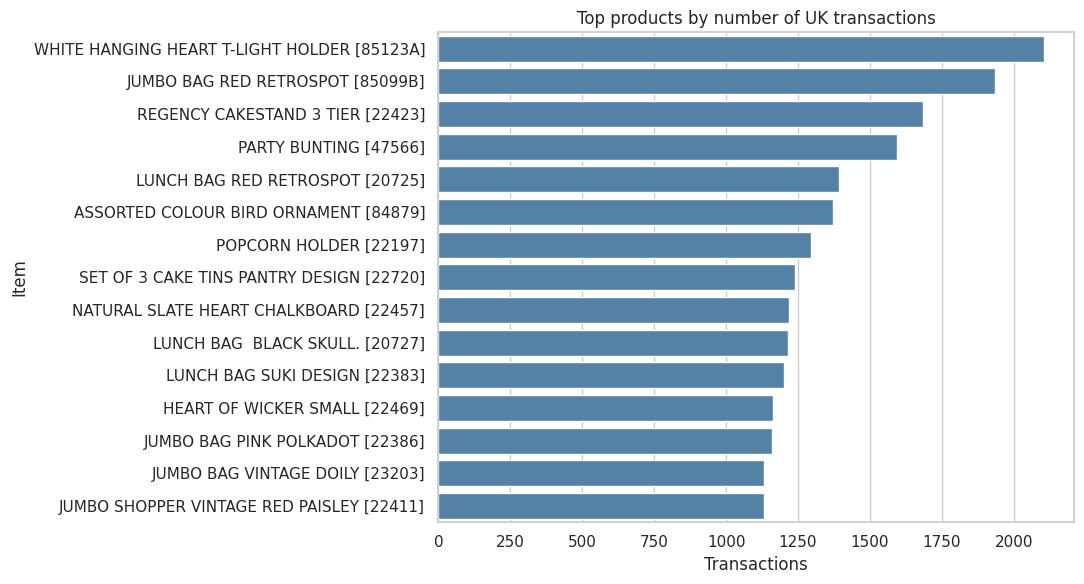

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [5]:
# StockCode is the item identifier; a stable description is used for readable labels.
item_labels = (clean.groupby("StockCode")["Description"]
               .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]).to_dict())
transactions = clean.groupby("InvoiceNo")["StockCode"].agg(lambda x: sorted(set(x))).tolist()
print("Baskets:", len(transactions))
print("Mean distinct items per basket:", round(np.mean([len(x) for x in transactions]), 2))

item_counts = clean.groupby("StockCode")["InvoiceNo"].nunique().sort_values(ascending=False).head(TOP_N)
top_items = pd.DataFrame({"Item": [item_labels.get(i, i) + " [" + i + "]" for i in item_counts.index],
                          "Transactions": item_counts.values})
plt.figure(figsize=(11, 6))
sns.barplot(data=top_items, y="Item", x="Transactions", color="steelblue")
plt.title("Top products by number of UK transactions")
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

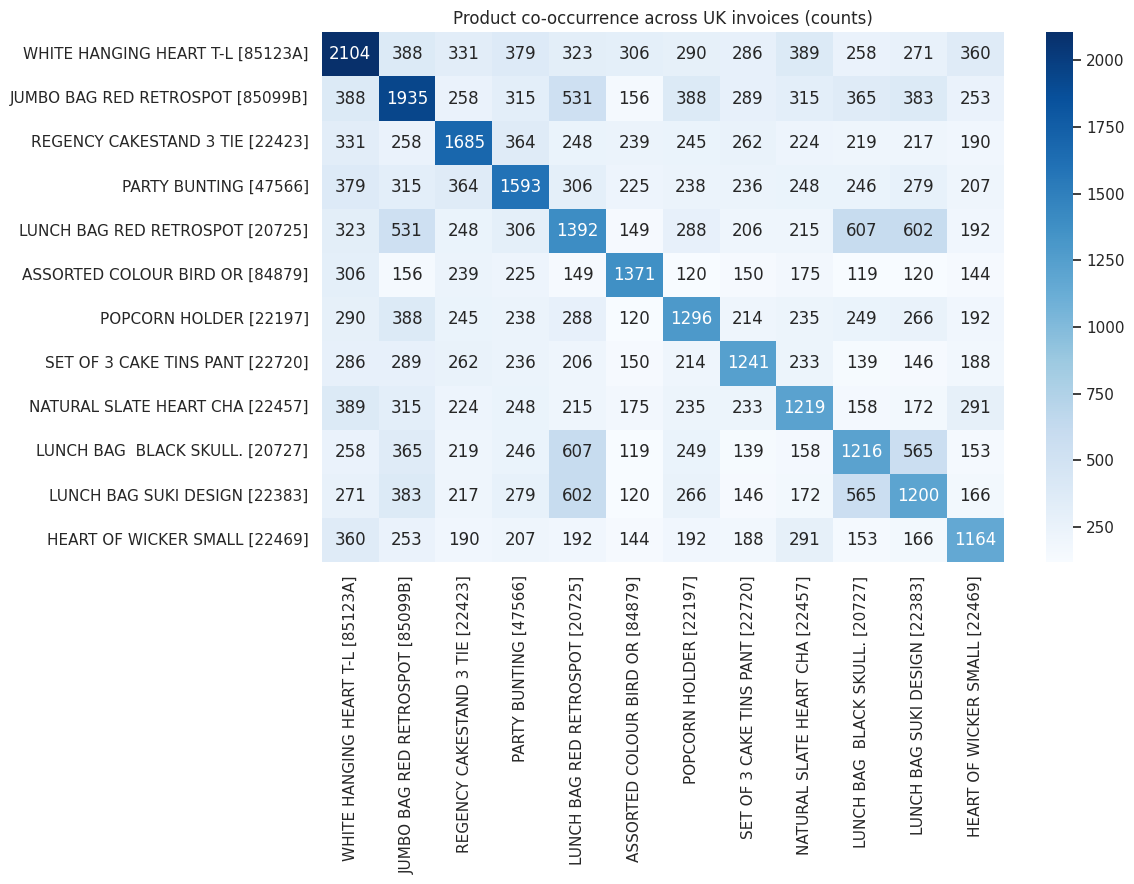

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# Co-occurrence counts for the 12 most common items, computed over all baskets.
top_codes = item_counts.index[:12].tolist()
co = pd.DataFrame(0, index=top_codes, columns=top_codes, dtype=int)
for basket in transactions:
    chosen = set(basket).intersection(top_codes)
    for a in chosen:
        for b in chosen:
            co.loc[a, b] += 1
short_labels = {c: item_labels.get(c, c)[:23] + " [" + c + "]" for c in top_codes}
co = co.rename(index=short_labels, columns=short_labels)
plt.figure(figsize=(12, 9))
sns.heatmap(co, cmap="Blues", annot=True, fmt="d")
plt.title("Product co-occurrence across UK invoices (counts)")
plt.tight_layout()
plt.show()

Basket encoding and memory considerations
A sparse one-hot encoded matrix records whether each product occurs in an invoice. To keep Apriori practical on a large dataset, retain products purchased in at least MIN_SUPPORT of invoices before running both algorithms. This filtering cannot remove any itemset meeting the same support threshold. Both methods receive exactly the same baskets and parameters.

In [7]:
n_baskets = len(transactions)
frequencies = clean.groupby("StockCode")["InvoiceNo"].nunique() / n_baskets
eligible = set(frequencies[frequencies >= MIN_SUPPORT].index)
filtered_transactions = [sorted(set(basket) & eligible) for basket in transactions]
encoder = TransactionEncoder()
encoded = encoder.fit(filtered_transactions).transform(filtered_transactions, sparse=True)
basket_df = pd.DataFrame.sparse.from_spmatrix(encoded, columns=encoder.columns_).astype(pd.SparseDtype(bool, False))
print("Binary basket matrix:", basket_df.shape)
print("Products meeting minimum support:", len(eligible))
assert basket_df.shape[0] == n_baskets

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Binary basket matrix: (18019, 301)
Products meeting minimum support: 301


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Step 2 – Apriori frequent itemset mining

In [8]:
start = time.perf_counter()
apriori_sets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True, low_memory=True)
apriori_seconds = time.perf_counter() - start
apriori_sets["length"] = apriori_sets["itemsets"].apply(len)
apriori_sets = apriori_sets.sort_values(["support", "length"], ascending=[False, True]).reset_index(drop=True)
print(f"Apriori: {len(apriori_sets)} itemsets in {apriori_seconds:.3f} seconds")
display(apriori_sets.head(20))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori: 414 itemsets in 3.325 seconds


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets,length
0,0.116766,(85123A),1
1,0.107387,(85099B),1
2,0.093512,(22423),1
3,0.088407,(47566),1
4,0.077252,(20725),1
5,0.076086,(84879),1
6,0.071924,(22197),1
7,0.068872,(22720),1
8,0.067651,(22457),1
9,0.067484,(20727),1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

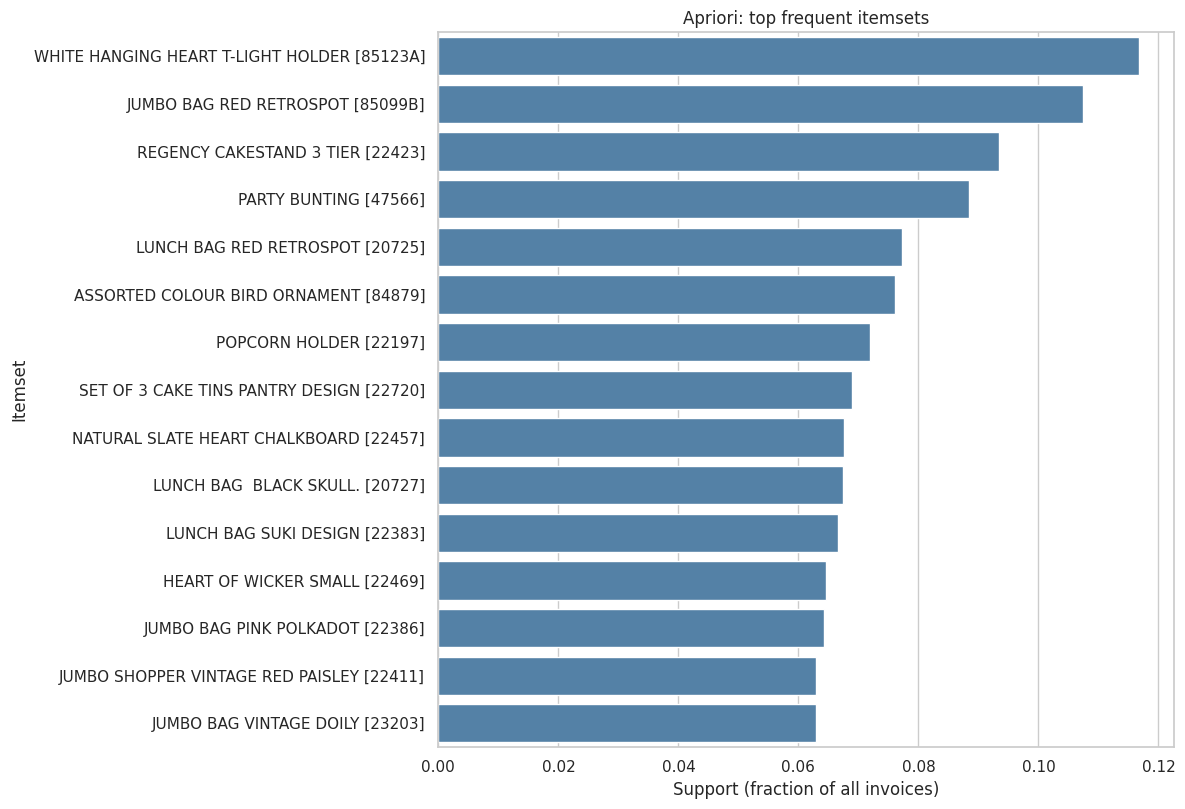

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
def itemset_name(items):
    return " + ".join(item_labels.get(i, i) + " [" + i + "]" for i in sorted(items))

def plot_top_itemsets(df, title, top_n=TOP_N):
    plot_df = df.head(top_n).copy()
    plot_df["Itemset"] = plot_df["itemsets"].apply(itemset_name)
    plt.figure(figsize=(12, max(5, len(plot_df) * 0.55)))
    sns.barplot(data=plot_df, x="support", y="Itemset", color="steelblue")
    plt.title(title)
    plt.xlabel("Support (fraction of all invoices)")
    plt.tight_layout()
    plt.show()
plot_top_itemsets(apriori_sets, "Apriori: top frequent itemsets")

Step 3 – FP-Growth frequent itemset mining

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

FP-Growth: 414 itemsets in 28.864 seconds


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets,length
0,0.116766,(85123A),1
1,0.107387,(85099B),1
2,0.093512,(22423),1
3,0.088407,(47566),1
4,0.077252,(20725),1
5,0.076086,(84879),1
6,0.071924,(22197),1
7,0.068872,(22720),1
8,0.067651,(22457),1
9,0.067484,(20727),1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

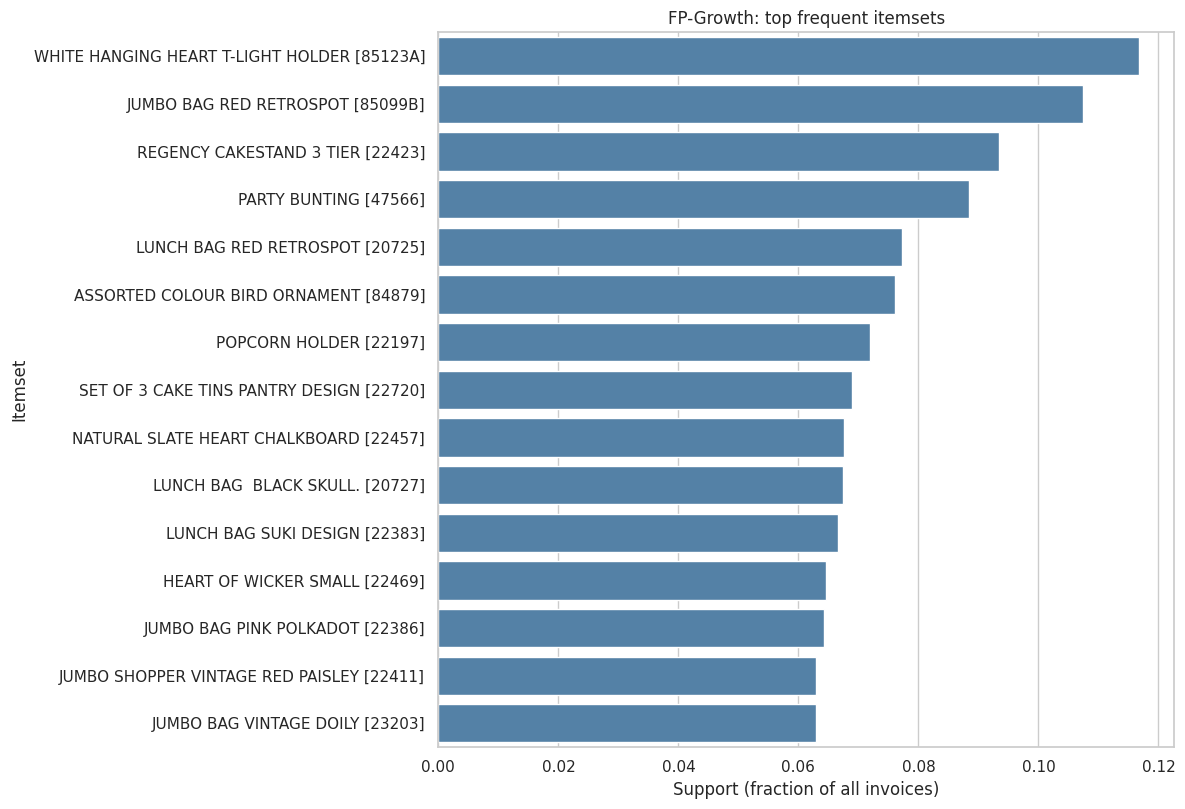

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
start = time.perf_counter()
fpgrowth_sets = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
fpgrowth_seconds = time.perf_counter() - start
fpgrowth_sets["length"] = fpgrowth_sets["itemsets"].apply(len)
fpgrowth_sets = fpgrowth_sets.sort_values(["support", "length"], ascending=[False, True]).reset_index(drop=True)
print(f"FP-Growth: {len(fpgrowth_sets)} itemsets in {fpgrowth_seconds:.3f} seconds")
display(fpgrowth_sets.head(20))
plot_top_itemsets(fpgrowth_sets, "FP-Growth: top frequent itemsets")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Itemsets and supports match. Maximum absolute difference: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithm,Execution seconds,Frequent itemsets
0,Apriori,3.324686,414
1,FP-Growth,28.864250,414


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

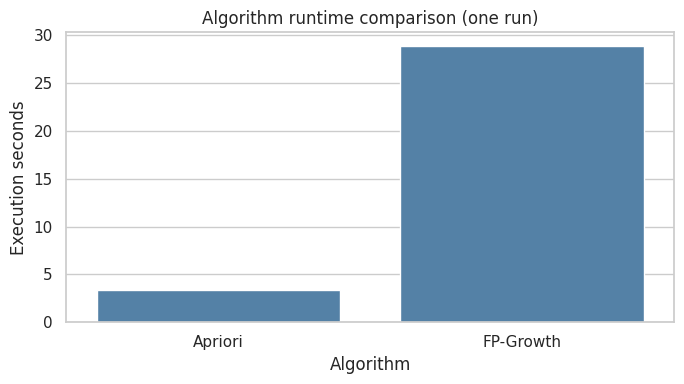

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
# Check that both algorithms produce the same frequent itemsets and supports.
a = apriori_sets.set_index("itemsets")["support"].sort_index(key=lambda idx: idx.map(lambda s: tuple(sorted(s))))
f = fpgrowth_sets.set_index("itemsets")["support"].sort_index(key=lambda idx: idx.map(lambda s: tuple(sorted(s))))
assert set(a.index) == set(f.index), "Algorithms produced different frequent itemsets"
max_diff = max((abs(a[k] - f[k]) for k in a.index), default=0.0)
assert max_diff < 1e-10, f"Support mismatch: {max_diff}"
print("Itemsets and supports match. Maximum absolute difference:", max_diff)
comparison = pd.DataFrame({"Algorithm": ["Apriori", "FP-Growth"],
                           "Execution seconds": [apriori_seconds, fpgrowth_seconds],
                           "Frequent itemsets": [len(apriori_sets), len(fpgrowth_sets)]})
display(comparison)
plt.figure(figsize=(7, 4))
sns.barplot(data=comparison, x="Algorithm", y="Execution seconds", color="steelblue")
plt.title("Algorithm runtime comparison (one run)")
plt.tight_layout()
plt.show()

Step 4 – Generate and analyze association rules


Support is the proportion of all invoices containing both antecedent and consequent. Confidence is the proportion of invoices containing the antecedent that also contain the consequent. Lift compares that confidence with the consequent's baseline occurrence; lift greater than 1 suggests positive association, not causation.

In [12]:
def generate_rules(frequent_sets):
    # Compatibility with mlxtend versions that require num_itemsets.
    try:
        rules = association_rules(frequent_sets[["support", "itemsets"]],
                                  metric="confidence", min_threshold=MIN_CONFIDENCE,
                                  num_itemsets=n_baskets)
    except TypeError:
        rules = association_rules(frequent_sets[["support", "itemsets"]],
                                  metric="confidence", min_threshold=MIN_CONFIDENCE)
    return rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

apriori_rules = generate_rules(apriori_sets)
fp_rules = generate_rules(fpgrowth_sets)
print("Apriori rules:", len(apriori_rules), "| FP-Growth rules:", len(fp_rules))
assert set(zip(apriori_rules["antecedents"], apriori_rules["consequents"])) == set(zip(fp_rules["antecedents"], fp_rules["consequents"]))

def readable_rules(rules):
    out = rules.copy()
    out["Antecedent"] = out["antecedents"].apply(itemset_name)
    out["Consequent"] = out["consequents"].apply(itemset_name)
    return out[["Antecedent", "Consequent", "support", "confidence", "lift"]]

display(readable_rules(apriori_rules).head(20))

In [13]:
def generate_rules(frequent_sets):
    # Compatibility with mlxtend versions that require num_itemsets.
    try:
        rules = association_rules(frequent_sets[["support", "itemsets"]],
                                  metric="confidence", min_threshold=MIN_CONFIDENCE,
                                  num_itemsets=n_baskets)
    except TypeError:
        rules = association_rules(frequent_sets[["support", "itemsets"]],
                                  metric="confidence", min_threshold=MIN_CONFIDENCE)
    return rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

apriori_rules = generate_rules(apriori_sets)
fp_rules = generate_rules(fpgrowth_sets)
print("Apriori rules:", len(apriori_rules), "| FP-Growth rules:", len(fp_rules))
assert set(zip(apriori_rules["antecedents"], apriori_rules["consequents"])) == set(zip(fp_rules["antecedents"], fp_rules["consequents"]))

def readable_rules(rules):
    out = rules.copy()
    out["Antecedent"] = out["antecedents"].apply(itemset_name)
    out["Consequent"] = out["consequents"].apply(itemset_name)
    return out[["Antecedent", "Consequent", "support", "confidence", "lift"]]

display(readable_rules(apriori_rules).head(20))

In [14]:
if not apriori_rules.empty:
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=apriori_rules, x="confidence", y="lift", size="support",
                    sizes=(30, 300), alpha=0.7, legend="brief")
    plt.axhline(1, color="gray", linestyle="--", label="Lift = 1")
    plt.title("Association rules: confidence vs lift (size = support)")
    plt.tight_layout()
    plt.show()
else:
    print("No rules met the confidence threshold; consider lowering MIN_CONFIDENCE and rerunning.")

In [15]:
# Report the strongest qualifying rule with a clear, reproducible interpretation.
if not apriori_rules.empty:
    best = apriori_rules.iloc[0]
    lhs = itemset_name(best["antecedents"])
    rhs = itemset_name(best["consequents"])
    print(f"Rule: IF [{lhs}] THEN [{rhs}]")
    print(f"Support = {best['support']:.2%}: both occur in this share of all invoices.")
    print(f"Confidence = {best['confidence']:.2%}: of invoices with the antecedent, this share also includes the consequent.")
    print(f"Lift = {best['lift']:.2f}: the consequent is this many times as likely with the antecedent as overall.")
    print("This is an association, not evidence that purchasing one item causes purchase of the other.")

Step 5 – Comparative analysis and challenges

In [16]:
winner = "FP-Growth" if fpgrowth_seconds < apriori_seconds else "Apriori" if apriori_seconds < fpgrowth_seconds else "Neither (tie)"
print("Faster in this measured run:", winner)
print(f"Apriori = {apriori_seconds:.3f}s; FP-Growth = {fpgrowth_seconds:.3f}s")
print("Both algorithms returned identical frequent itemsets:", set(a.index) == set(f.index))
print("Both algorithms returned identical rule pairs:", set(zip(apriori_rules.antecedents, apriori_rules.consequents)) == set(zip(fp_rules.antecedents, fp_rules.consequents)))

Discussion


- Apriori: Utilizes the downward closure of support to build and prune candidate itemsets. The cost of generating candidates will increase with growing number of frequent items.
- FP-Growth: Constructs the FP-tree from the transactions and mines the conditional patterns without having to generate the same candidate itemsets. This method may be more efficient than Apriori for large and dense transactional databases and is benchmarked with respect to execution time above.
- Fairness: Both approaches operate on exactly the same UK invoices, one-hot encoded items, and support. Execution time includes only mining and no common loading time and pre-processing.
- Data issues and their resolution: Filtered out canceled invoices, returns, missing product IDs, negative quantities/price, and duplicated entries in invoices-products table. Limited to UK transactions to narrow the market. Sparse encoding and support-safe one-item pruning applied to control memory usage.
- Insights: Lift value alone is not enough: analyze support and confidence in order not to misinterpret rare association rules. Rules reveal purchasing behavior and do not imply any causality.
Conclusion

Conclusion

Both algorithms must generate similar itemsets and rules with the help of the same baskets and parameters. The runtime comparison presented above allows us to determine which version of the algorithm was faster on the chosen transactions. The generated rules can be used for further decisions concerning product placement, etc.

Dataset reference
Chen, D. (2015). Online Retail [Dataset]. UCI